# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "caiodouglas/dados-csv-clientes-banco-stone"
)

print("Dataset baixado em:", path)

100%|██████████| 239k/239k [00:00<00:00, 21.4MB/s]

Extracting files...
Dataset baixado em: /root/.cache/kagglehub/datasets/caiodouglas/dados-csv-clientes-banco-stone/versions/1


In [ ]:
import os
import pandas as pd

path = "/root/.cache/kagglehub/datasets/caiodouglas/dados-csv-clientes-banco-stone/versions/1"

arquivos_csv = [f for f in os.listdir(path) if f.endswith(".csv")]

print(arquivos_csv)



['Python_M10_support material.csv']


In [ ]:
df = pd.read_csv(f"{path}/Python_M10_support material.csv")

## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(10127, 16)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   id                       10127 non-null  int64 
 1   default                  10127 non-null  int64 
 2   idade                    10127 non-null  int64 
 3   sexo                     10127 non-null  object
 4   dependentes              10127 non-null  int64 
 5   escolaridade             10127 non-null  object
 6   estado_civil             10127 non-null  object
 7   salario_anual            10127 non-null  object
 8   tipo_cartao              10127 non-null  object
 9   meses_de_relacionamento  10127 non-null  int64 
 10  qtd_produtos             10127 non-null  int64 
 11  iteracoes_12m            10127 non-null  int64 
 12  meses_inativo_12m        10127 non-null  int64 
 13  limite_credito           10127 non-null  object
 14  valor_transacoes_12m     10127 non-nul

In [ ]:
df.describe()

,id,default,idade,dependentes,meses_de_relacionamento,qtd_produtos,iteracoes_12m,meses_inativo_12m,qtd_transacoes_12m
count,1.012700e+04,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,0.160660,46.325960,2.346203,35.928409,3.812580,2.455317,2.341167,64.858695
std,3.690378e+07,0.367235,8.016814,1.298908,7.986416,1.554408,1.106225,1.010622,23.472570
min,7.080821e+08,0.000000,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,10.000000
25%,7.130368e+08,0.000000,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,45.000000
50%,7.179264e+08,0.000000,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,67.000000
75%,7.731435e+08,0.000000,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,81.000000
max,8.283431e+08,1.000000,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,139.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [ ]:
df["status_financeiro"] = np.where(df["default"] > 0, "Inadimplente", "Adimplente")
df["status_financeiro"].value_counts()
df.drop(columns=["default"], inplace=True)
df.head()

,id,idade,sexo,dependentes,escolaridade,estado_civil,salario_anual,tipo_cartao,meses_de_relacionamento,qtd_produtos,iteracoes_12m,meses_inativo_12m,limite_credito,valor_transacoes_12m,qtd_transacoes_12m,status_financeiro
0,768805383,45,M,3,ensino medio,casado,$60K - $80K,blue,39,5,3,1,"12.691,51","1.144,90",42,Adimplente
1,818770008,49,F,5,mestrado,solteiro,menos que $40K,blue,44,6,2,1,"8.256,96","1.291,45",33,Adimplente
2,713982108,51,M,3,mestrado,casado,$80K - $120K,blue,36,4,0,1,"3.418,56","1.887,72",20,Adimplente
3,769911858,40,F,4,ensino medio,na,menos que $40K,blue,34,3,1,4,"3.313,03","1.171,56",20,Adimplente
4,709106358,40,M,3,sem educacao formal,casado,$60K - $80K,blue,21,5,0,1,"4.716,22","816,08",28,Adimplente


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
id,0
idade,0
sexo,0
dependentes,0
escolaridade,0
estado_civil,0
salario_anual,0
tipo_cartao,0
meses_de_relacionamento,0
qtd_produtos,0


**PROCURANDO NAS VARIÁVEIS QUALITATIVAS POR VALORES AUSENTES ( Identifiquei em outra ocasião que variáveis qualitativas possuiam o valor "na" no lugar do NaN.)**

In [ ]:
df["sexo"].unique()

array(['M', 'F'], dtype=object)

In [ ]:
df["escolaridade"].unique()

array(['ensino medio', 'mestrado', 'sem educacao formal', 'na',
       'graduacao', 'doutorado'], dtype=object)

In [ ]:
(df["escolaridade"] == "na").sum()

np.int64(1519)

In [ ]:
df.loc[df["escolaridade"] == "na","escolaridade"] = pd.NA

In [ ]:
df["estado_civil"].unique()

array(['casado', 'solteiro', 'na', 'divorciado'], dtype=object)

In [ ]:
(df["estado_civil"] == "na").sum()

np.int64(749)

In [ ]:
df.loc[df["estado_civil"] == "na","estado_civil"] = pd.NA

In [ ]:
df["salario_anual"].unique()

array(['$60K - $80K', 'menos que $40K', '$80K - $120K', '$40K - $60K',
       '$120K +', 'na'], dtype=object)

In [ ]:
(df["salario_anual"]=="na").sum()

np.int64(1112)

In [ ]:
df.loc[df["salario_anual"]=="na","salario_anual"] = pd.NA

In [ ]:
df["tipo_cartao"].unique()

array(['blue', 'gold', 'silver', 'platinum'], dtype=object)

In [ ]:
df["status_financeiro"].unique()

array(['Adimplente', 'Inadimplente'], dtype=object)

**Discussao:** Alguma feature tem dados ausentes nos seus dados?

***Resposta***: O dataset possui dados ausentes em 3 de suas colunas.

---

"escolaridade", "estado_civil","salario_anual". As 3 colunas são qualitativas e não estavam marcadas como NaN e sim como "na". Foi realizado a mudança para facilitar a análisa e posterior transformações e manipulações

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**


*Como os dados foram coletados:*
**- O dataset foi encontrado no Kaggle. Ele não possui descrição. O título "Dados csv clientes banco stone" indica que são dados de clientes do banco stone, porém não indica de qual forma foi obtido**

*Qual a natureza da fonte de dados:*
**- A principio, é possível assumir que foram fruto de algum tipo de formúlario ou processo báncario.**

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['escolaridade', 'estado_civil', 'salario_anual']
escolaridade     1519
estado_civil      749
salario_anual    1112
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

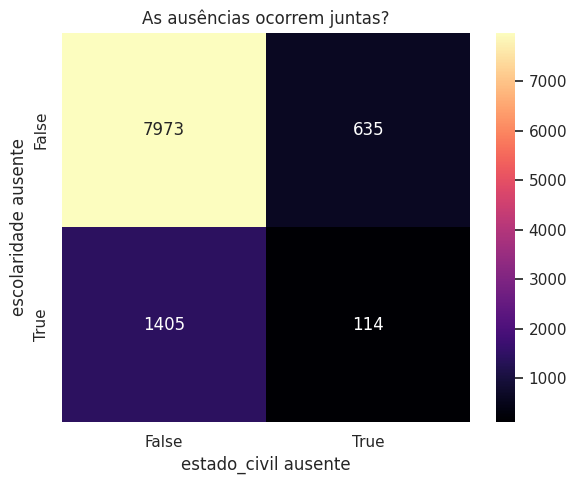

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

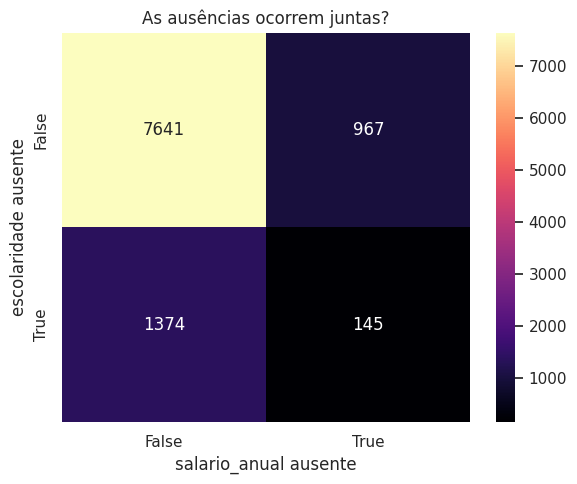

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[2]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[2]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

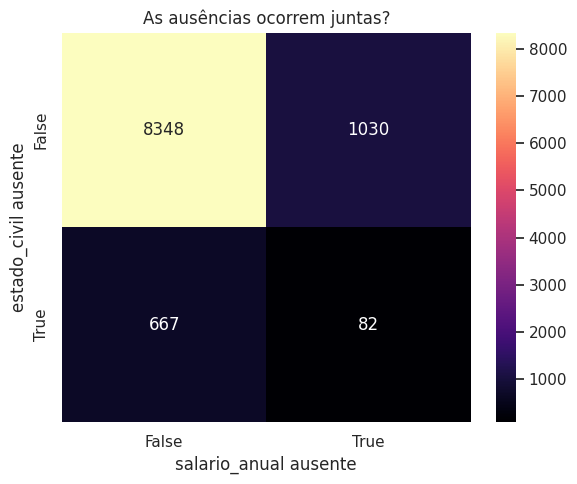

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[1]].isna(), df[cols_com_ausentes[2]].isna(),
            rownames=[f"{cols_com_ausentes[1]} ausente"], colnames=[f"{cols_com_ausentes[2]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

**Resposta:** análise de ausências em conjuntas não indicam necessariamente para um tipo de ausência em éspecifico, com a maioria das ausẽncias em conjunto transitando entre 10 a 20% entre as classes envolvidas.
A variável de sálario anual e escolaridade sendo as que mais possuem ausências podem indicar que as respostas poderiam ser um pouco desconfortáveis aos participantes, o mesmo pode ocorrer também com estado cívil, talvez indicando uma tendência de ser não rândomica ou totalmente aléatoria devido ao baixo número de ocorrências.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
df["id"] = df["id"].astype(str)

(transformando id para String, colocando ela como variável qualitativa e não quantitativa).

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   id                       10127 non-null  object
 1   idade                    10127 non-null  int64 
 2   sexo                     10127 non-null  object
 3   dependentes              10127 non-null  int64 
 4   escolaridade             8608 non-null   object
 5   estado_civil             9378 non-null   object
 6   salario_anual            9015 non-null   object
 7   tipo_cartao              10127 non-null  object
 8   meses_de_relacionamento  10127 non-null  int64 
 9   qtd_produtos             10127 non-null  int64 
 10  iteracoes_12m            10127 non-null  int64 
 11  meses_inativo_12m        10127 non-null  int64 
 12  limite_credito           10127 non-null  object
 13  valor_transacoes_12m     10127 non-null  object
 14  qtd_transacoes_12m       10127 non-nul

In [ ]:
VARS_QUANT = ["idade", "dependentes", "meses_de_relacionamento", "qtd_produtos", "iteracoes_12m",
              "meses_inativo_12m","qtd_transacoes_12m"]
VARS_QUALI = ["id", "sexo", "escolaridade", "estado_civil", "salario_anual", "tipo_cartao", "limite_credito", "valor_transacoes_12m","status_financeiro"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)
 #   Column                   Non-Null Count  Dtype


,mean,median,std,min,max,skewness,kurtosis
idade,46.33,46.00,8.02,26.00,73.00,-0.03,-0.29
dependentes,2.35,2.00,1.30,0.00,5.00,-0.02,-0.68
meses_de_relacionamento,35.93,36.00,7.99,13.00,56.00,-0.11,0.40
qtd_produtos,3.81,4.00,1.55,1.00,6.00,-0.16,-1.01
iteracoes_12m,2.46,2.00,1.11,0.00,6.00,0.01,0.00
meses_inativo_12m,2.34,2.00,1.01,0.00,6.00,0.63,1.10
qtd_transacoes_12m,64.86,67.00,23.47,10.00,139.00,0.15,-0.37


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

**Resposta:** variáveis de um modo geral estão bem distruídas, pelo fato do curtose de todas as variáveis indicarem uma curva platícurtica. A variável que possui maior dissônancia relativo à simetria é a de "meses inativos". Sua assimetria positiva indica uma maior quantidade de valores extremos que puxam a "cauda" para direita, porém que se concentram mais à esquerda ( valores pequenos de inatividade).

### Distribuições de dados

Comparação entre número de pessoas Adimplentes e Inadimplentes.


In [ ]:
(df["status_financeiro"]=="Adimplente").sum()

np.int64(8500)

In [ ]:
(df["status_financeiro"]=="Inadimplente").sum()

np.int64(1627)

O dataset possui bem mais variáveis de clientes adimplentes do que inadimplentes

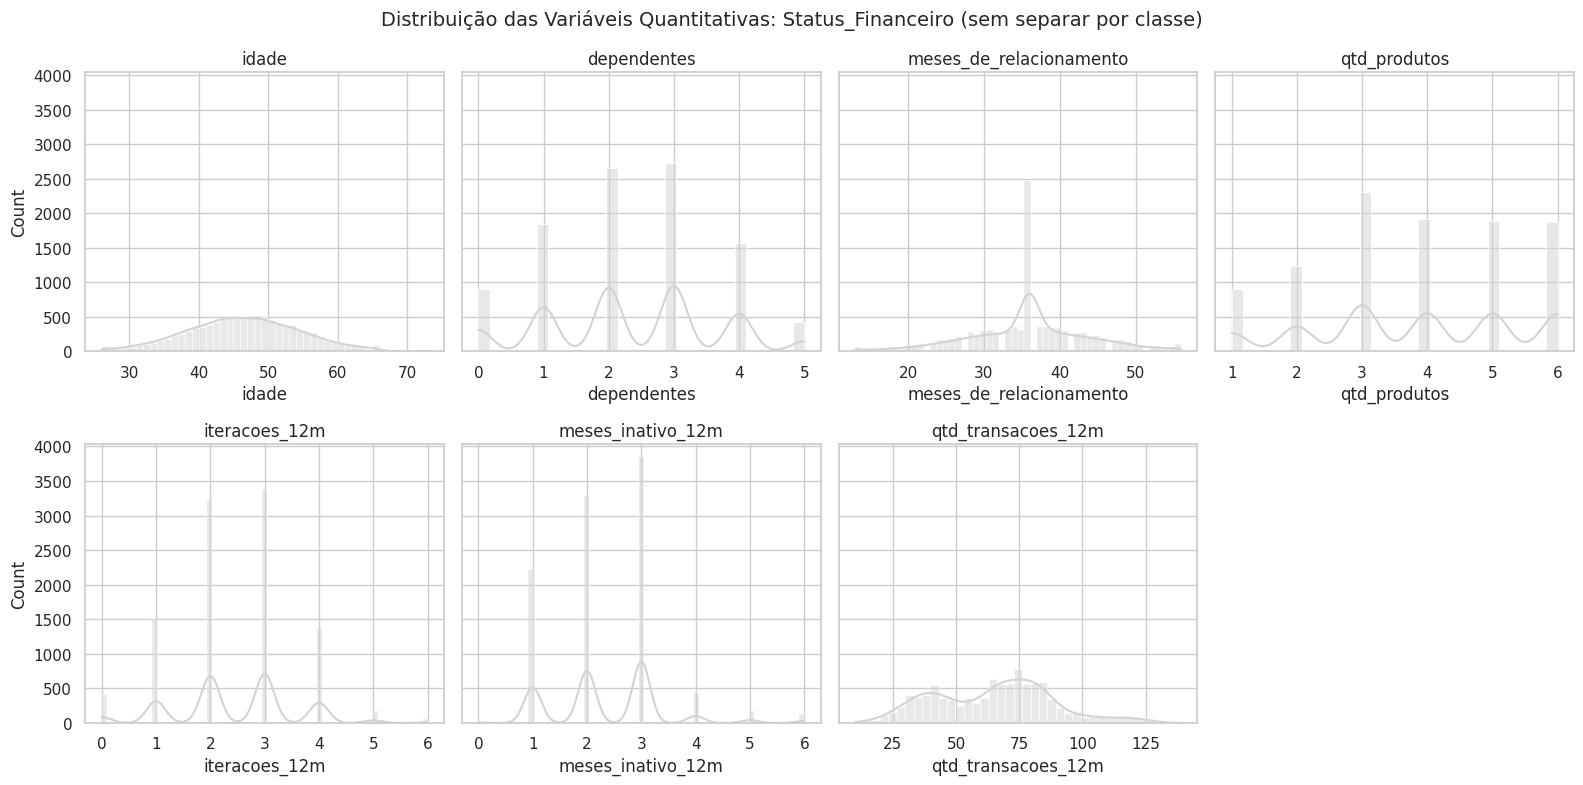

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Status_Financeiro (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

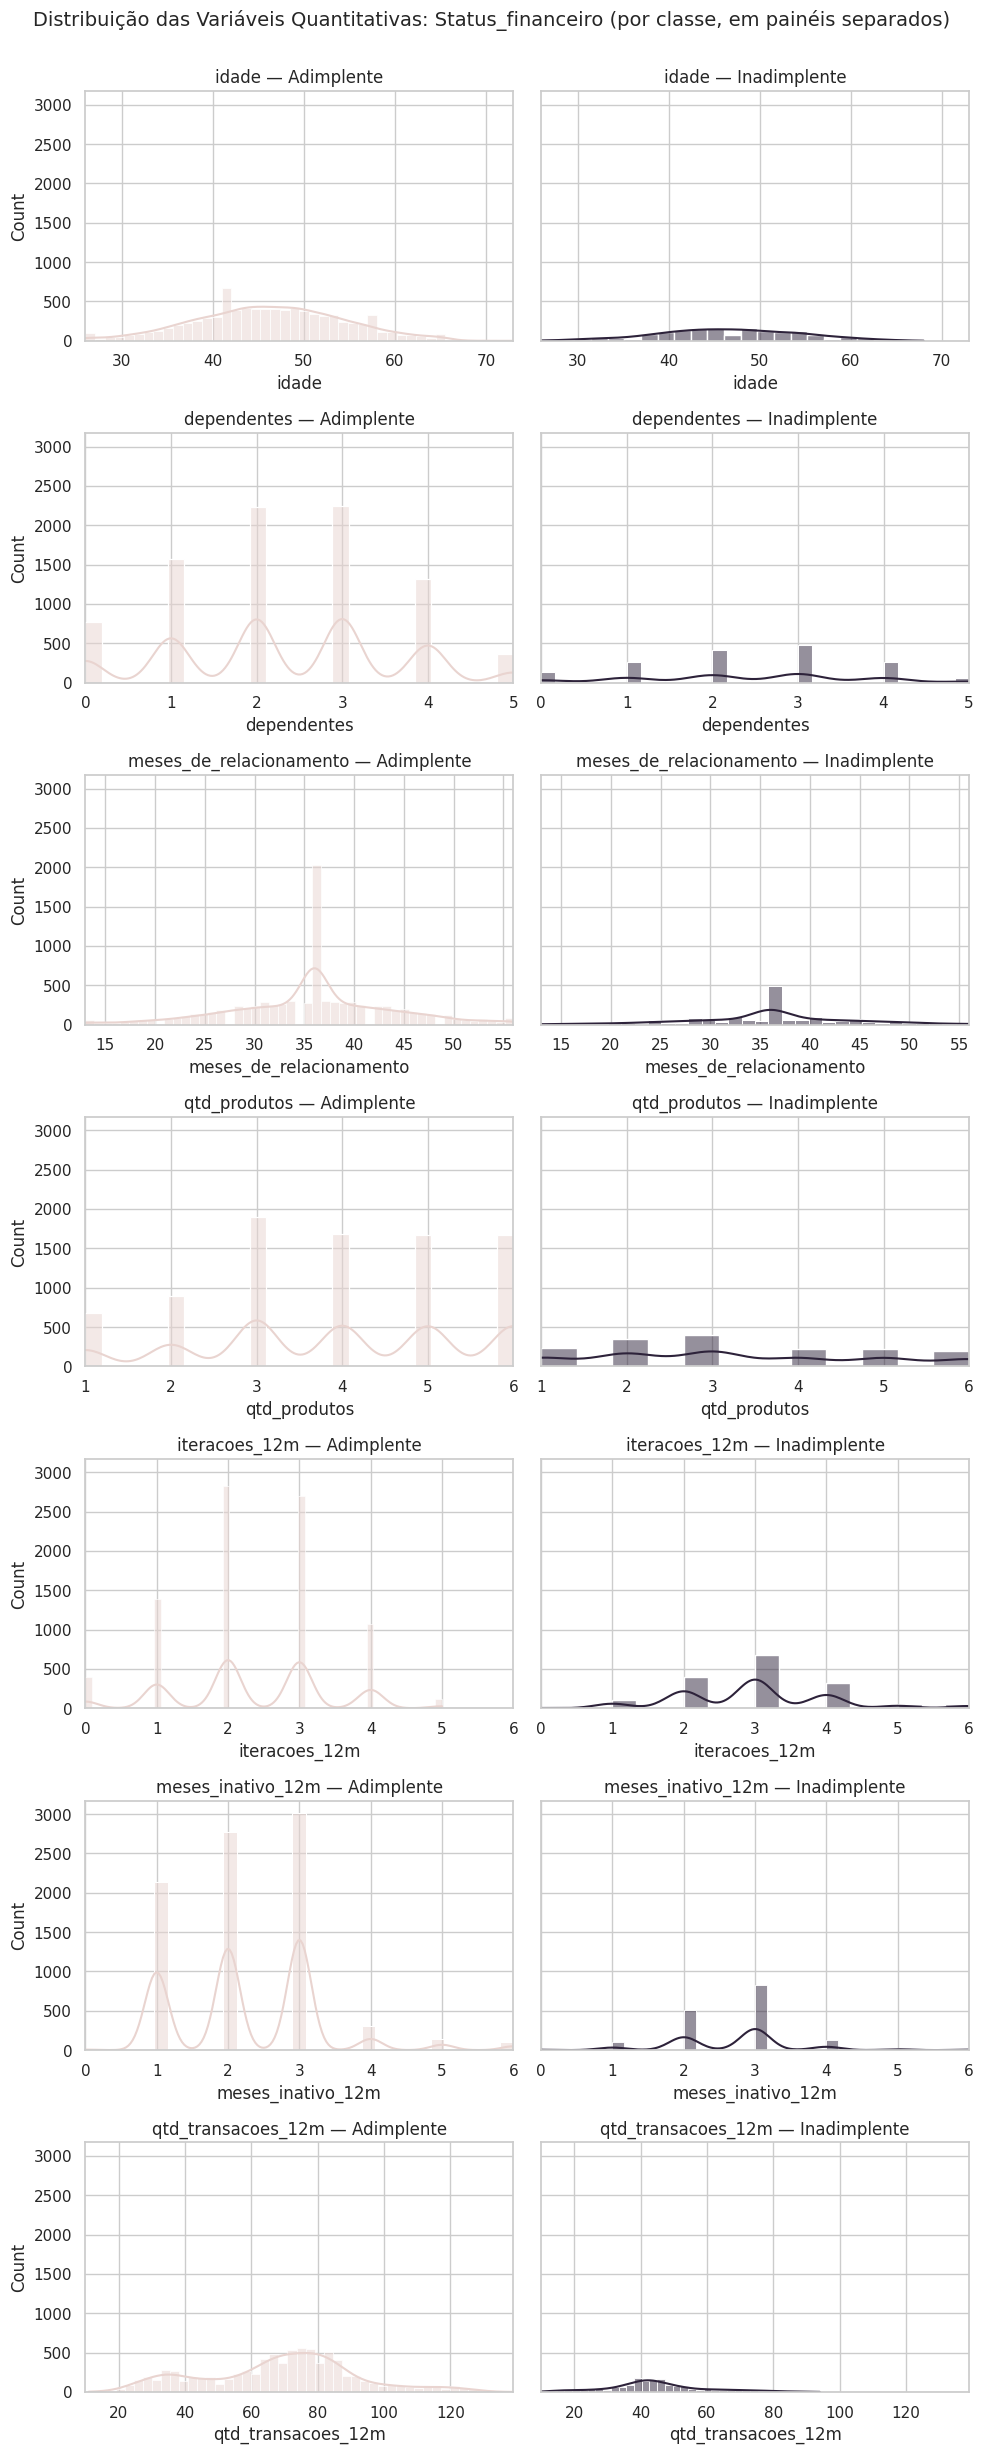

In [ ]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Adimplente", COR_CONTEXTO), ("Inadimplente", COR_DESTAQUE)]):
        subset = df[df["status_financeiro"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Status_financeiro (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Adimplente" e "Inadimplente"?

**Resposta:** variáveis parecem obedecer a mesmo compartamento entre as classes, porém em escalas menores, visto que o dataset possui bem mais variáveis de clientes adimplentes do que inadimplentes. A variável que mais distoa é a variável de "qtd_transacoes". Clientes inaadimplentes possuem quantidades de transações nos últimos 12 meses consideravelmente menores do que clientes adimplentes.


#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10127.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — qtd_transacoes_12m: estatística=0.9839, p-valor=2.887e-32
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


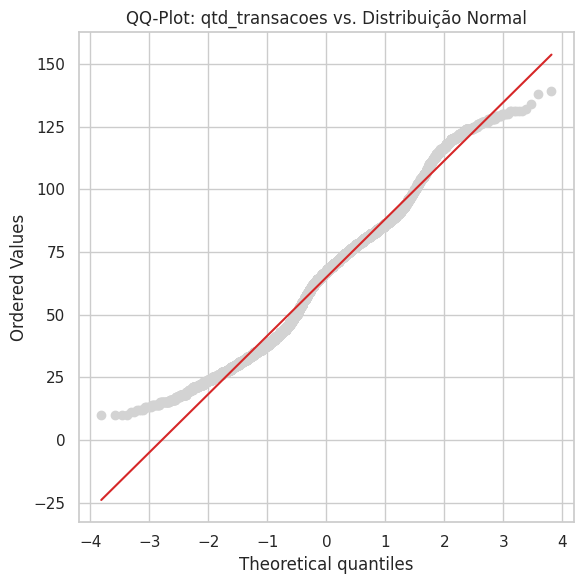

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df["qtd_transacoes_12m"].dropna())
print(f"Shapiro-Wilk — qtd_transacoes_12m: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — colesterol"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["qtd_transacoes_12m"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: qtd_transacoes vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
idade,0.9960,0.0,True
dependentes,0.9369,0.0,True
meses_de_relacionamento,0.9769,0.0,True
qtd_produtos,0.9203,0.0,True
iteracoes_12m,0.9283,0.0,True
meses_inativo_12m,0.8677,0.0,True
qtd_transacoes_12m,0.9839,0.0,True


**Nenhuma das variáveis quantitativas obedece uma curva normal**

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

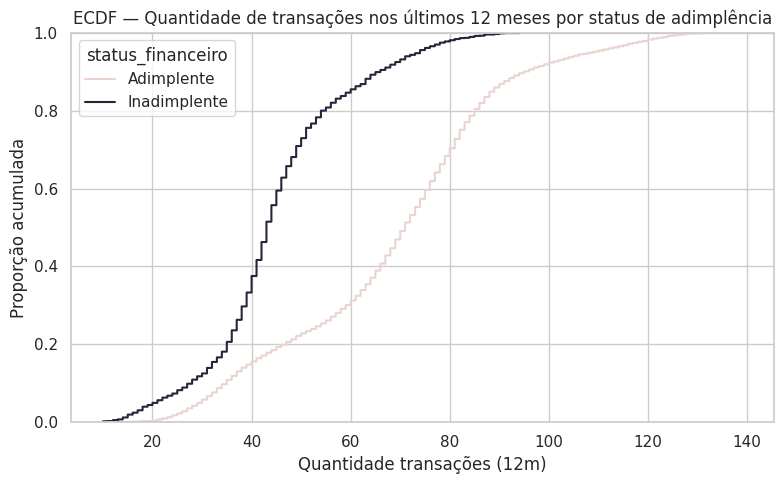

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="qtd_transacoes_12m", hue="status_financeiro",
             palette={"Adimplente": COR_CONTEXTO, "Inadimplente": COR_DESTAQUE})
plt.title("ECDF — Quantidade de transações nos últimos 12 meses por status de adimplência")
plt.xlabel("Quantidade transações (12m)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

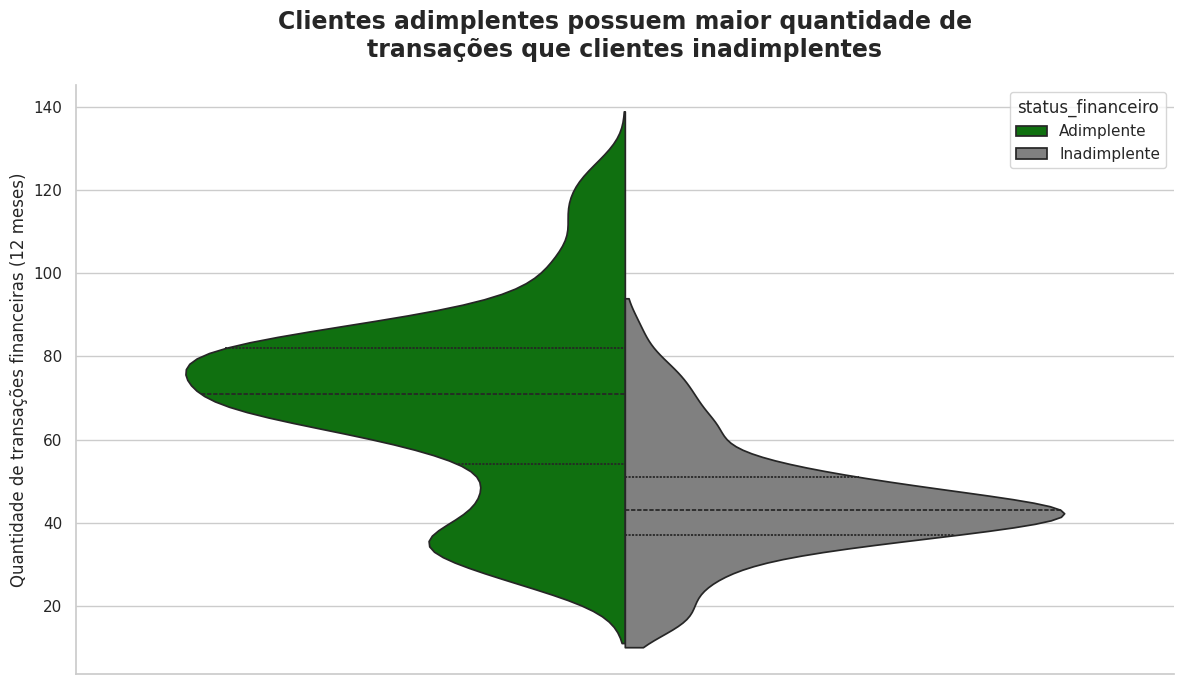

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar os estados financeiros desejados
df_plot = df[
    df["status_financeiro"].isin(["Adimplente", "Inadimplente"])
].copy()

# Manter apenas uma categoria no eixo x para formar um único violino
df_plot["grupo"] = "Clientes"

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(12, 7))

sns.violinplot(
    data=df_plot,
    x="grupo",
    y="qtd_transacoes_12m",
    hue="status_financeiro",
    hue_order=["Adimplente", "Inadimplente"],
    split=True,
    palette={
        "Adimplente": "green",
        "Inadimplente": "gray"
    },
    inner="quartile",
    cut=0,
    ax=ax
)

ax.set_title(
    "Clientes adimplentes possuem maior quantidade de\n"
    "transações que clientes inadimplentes",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel("Quantidade de transações financeiras (12 meses)", fontsize=12)
ax.set_xticks([])

sns.despine()
plt.tight_layout()
plt.show()

Esse gráfico mostra a diferença já comentada no histograma anterior. Há uma boa diferença entre a quantidade de transações realizadas por pessoas adimplentes e por pessoas inadimplentes

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

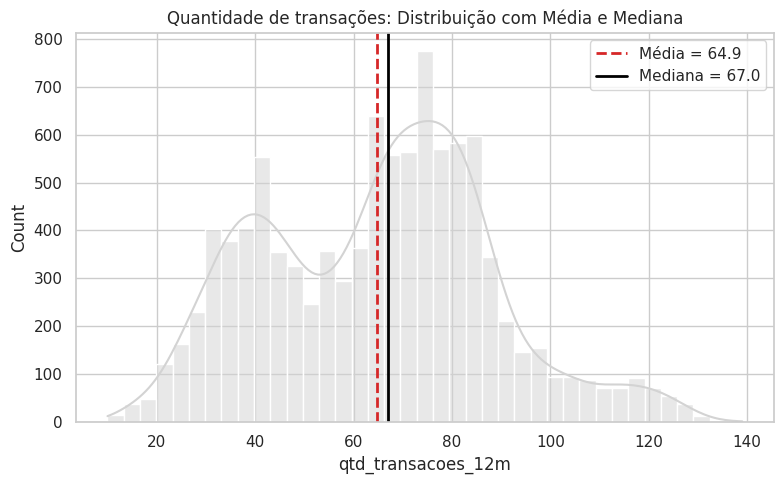

In [ ]:
media_qtd_transacoes = df["qtd_transacoes_12m"].mean()
mediana_qtd_trasacoes = df["qtd_transacoes_12m"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="qtd_transacoes_12m", kde=True, color=COR_NEUTRA)
plt.axvline(media_qtd_transacoes, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_qtd_transacoes:.1f}")
plt.axvline(mediana_qtd_trasacoes, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_qtd_trasacoes:.1f}")
plt.title("Quantidade de transações: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

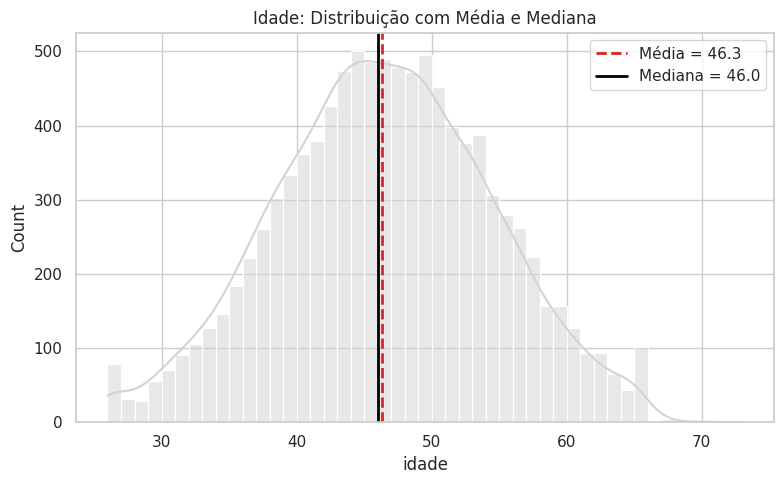

In [ ]:
media_idade = df["idade"].mean()
mediana_idade = df["idade"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="idade", kde=True, color=COR_NEUTRA)
plt.axvline(media_idade, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_idade:.1f}")
plt.axvline(mediana_idade, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_idade:.1f}")
plt.title("Idade: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

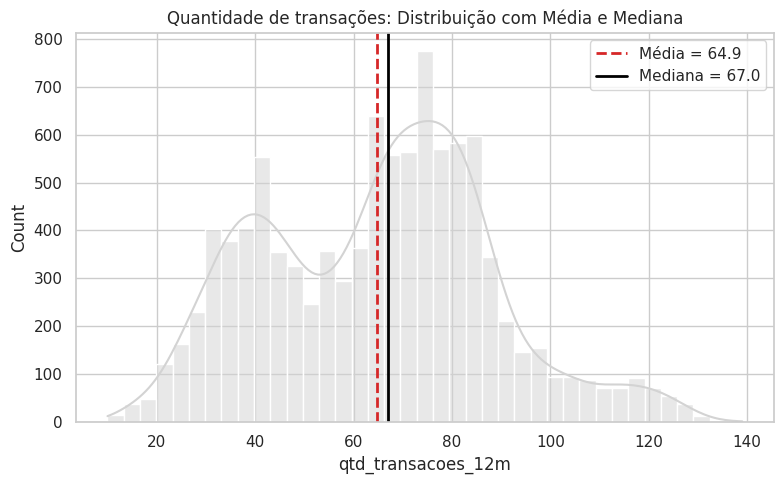

In [ ]:
media_qtd_transacoes = df["qtd_transacoes_12m"].mean()
mediana_qtd_trasacoes = df["qtd_transacoes_12m"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="qtd_transacoes_12m", kde=True, color=COR_NEUTRA)
plt.axvline(media_qtd_transacoes, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_qtd_transacoes:.1f}")
plt.axvline(mediana_qtd_trasacoes, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_qtd_trasacoes:.1f}")
plt.title("Quantidade de transações: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

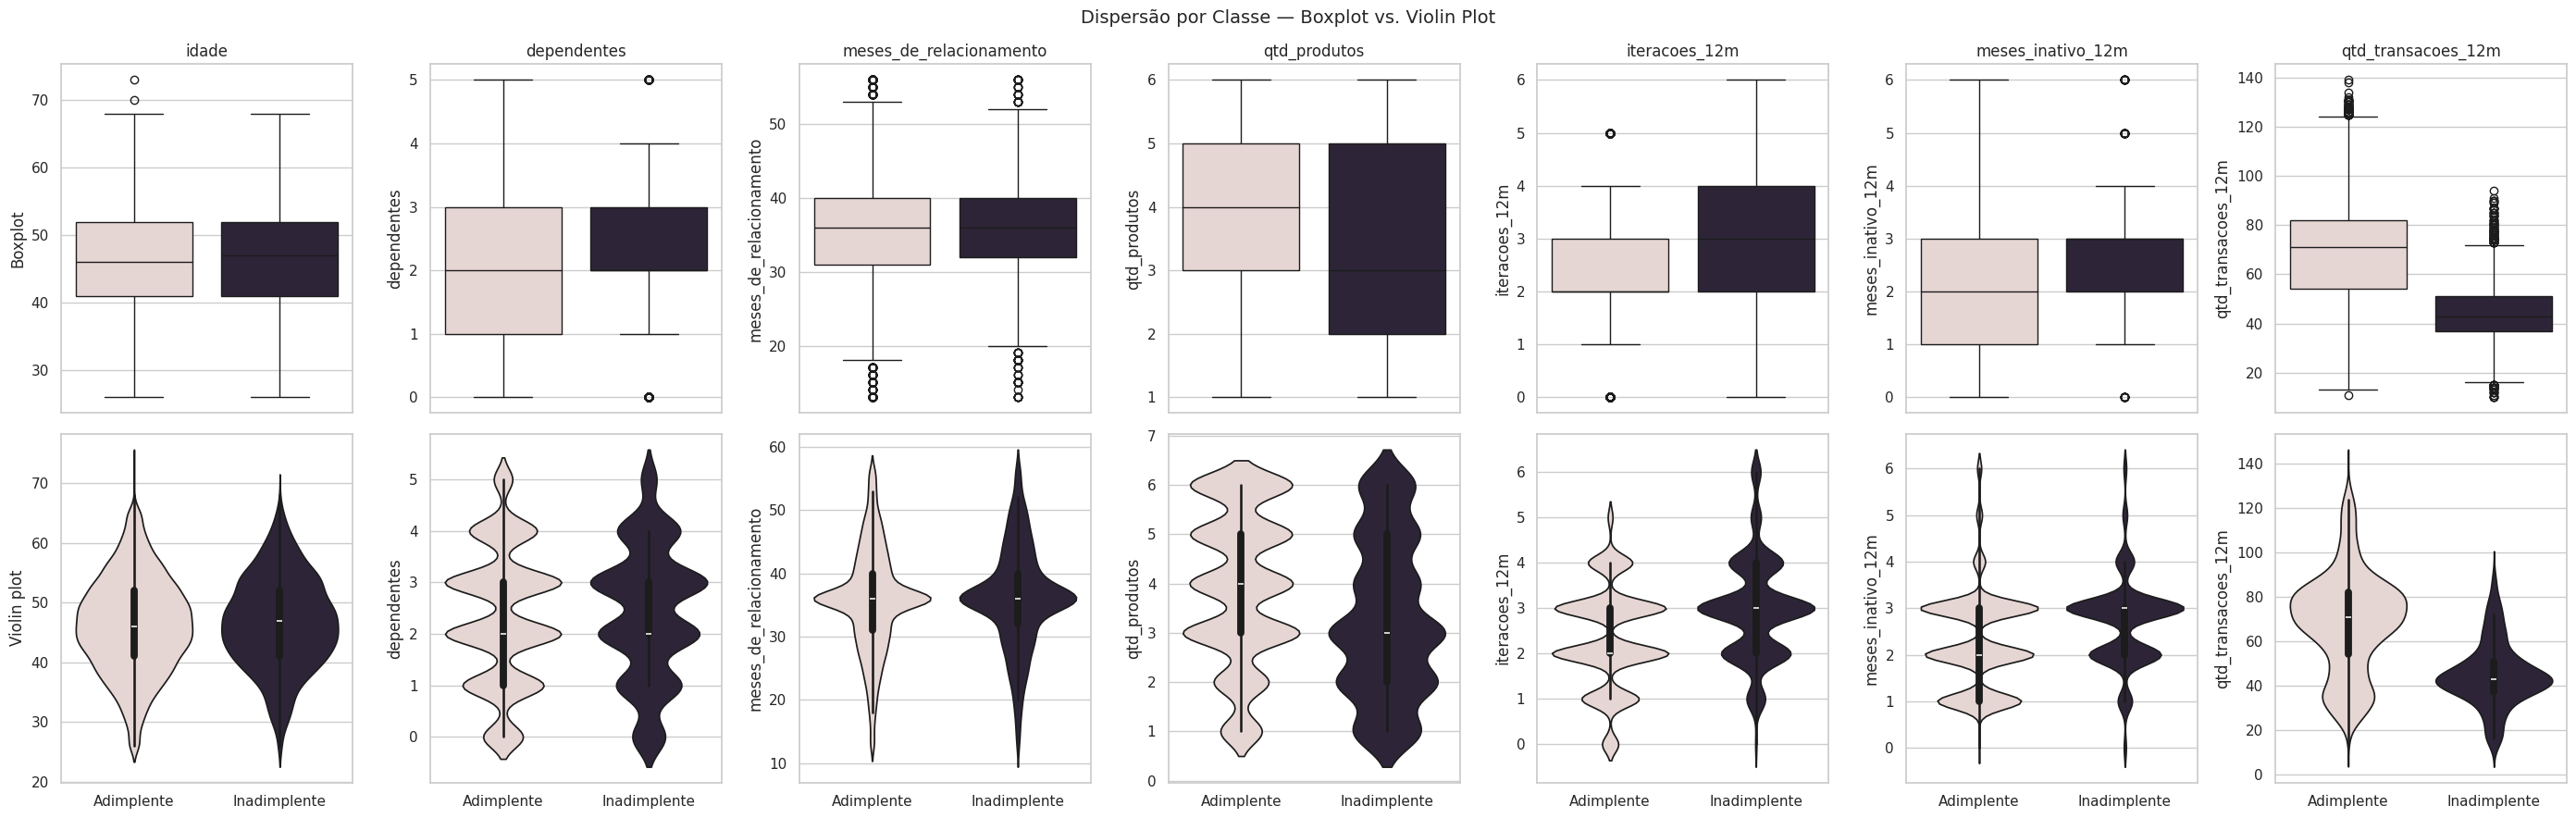

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Adimplente": COR_CONTEXTO, "Inadimplente": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="status_financeiro", y=col, hue="status_financeiro",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="status_financeiro", y=col, hue="status_financeiro",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

**Resposta:** A variável quantidade de transações, como já discutido, apresenta grande variação entre as classes. As maiores diferenças se veem em variáveis que não são contínuas, e possuem uma discrepância entre uma unidade para mais ou para menos, que devido à escala do plot acaba por parecer algo mais discrepante.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
idade,24.5,68.5,2.0
dependentes,-2.0,6.0,0.0
meses_de_relacionamento,17.5,53.5,386.0
qtd_produtos,0.0,8.0,0.0
iteracoes_12m,0.5,4.5,629.0
meses_inativo_12m,0.5,4.5,331.0
qtd_transacoes_12m,-9.0,135.0,2.0


### Visualizando os Outliers

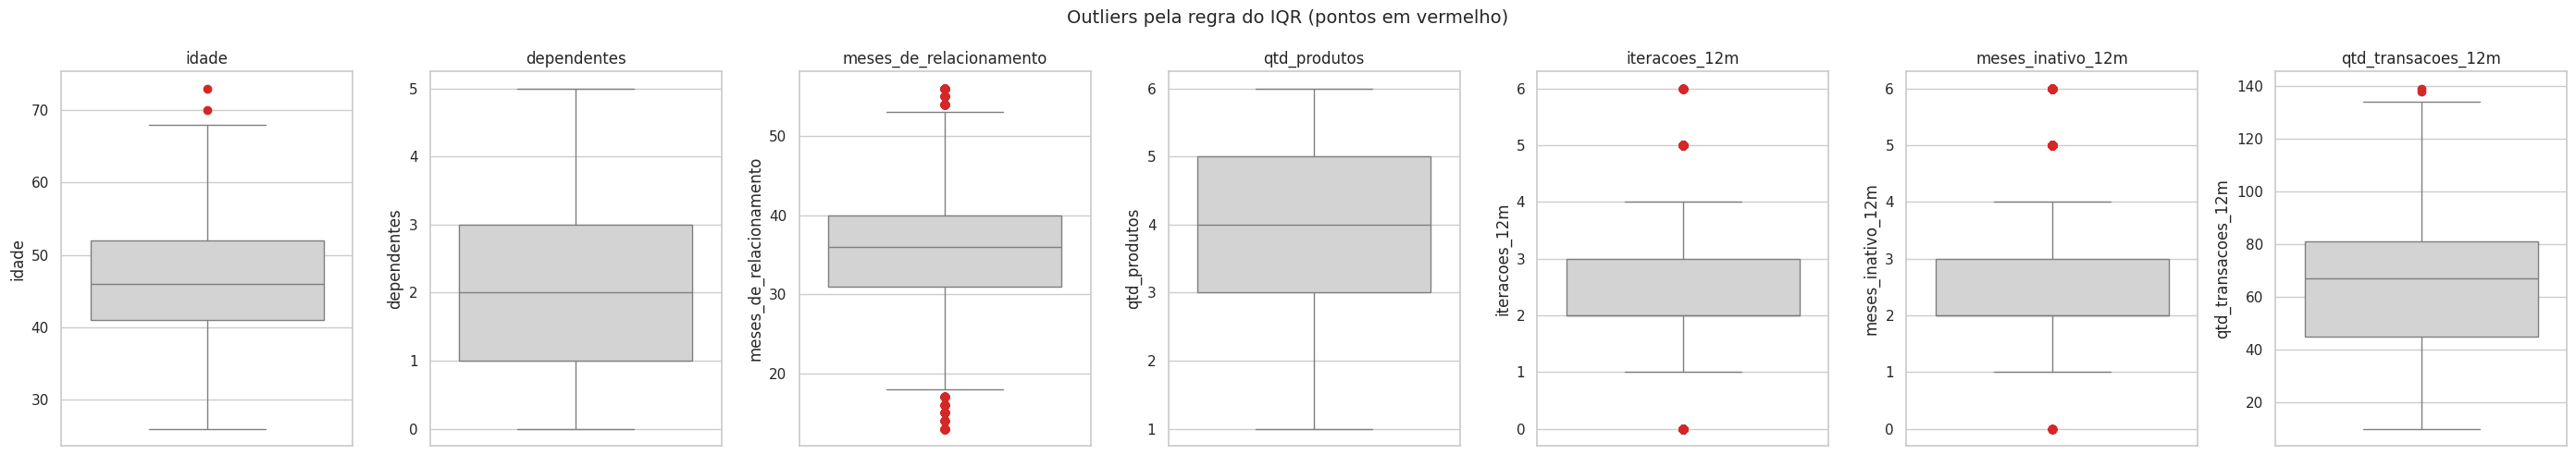

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

**Resposta:** A principio nenhum outlier viola o domínio ou apresenta-se como falha, apresentando-se muito mais como outlier estátistico.

### Decidindo o Tratamento dos Dados Ausentes

Pelo fato do dataset não ter informações sobre sua procedência de forma suficiente, não é possível determinar com segurança se a ausência possui viés.
Pelo fato de serem muitos valores ( entre 10 a 15% do dataset) não faz muito sentido remove-los, portanto será imputada a moda nesses dados ( Pelo fato deles serem qualitativos).

In [ ]:
df_antes = df

In [ ]:
moda = df["escolaridade"].mode()[0]
df.loc[df["escolaridade"].isna(), "escolaridade"] = moda

In [ ]:
moda = df["estado_civil"].mode()[0]
df.loc[df["escolaridade"].isna(), "escolaridade"] = moda

In [ ]:
moda = df["salario_anual"].mode()[0]
df.loc[df["salario_anual"].isna(),"salario_anual"] = moda

### Decidindo o Tratamento dos Outliers

Pelo fato de nenhum outlier "quebrar" o domínio, creio que eles se encaixam como estátisticos, portanto não faz sentido remove-los, visto que essa variedade representa uma situação real que não pode ser simplesmente descartada.

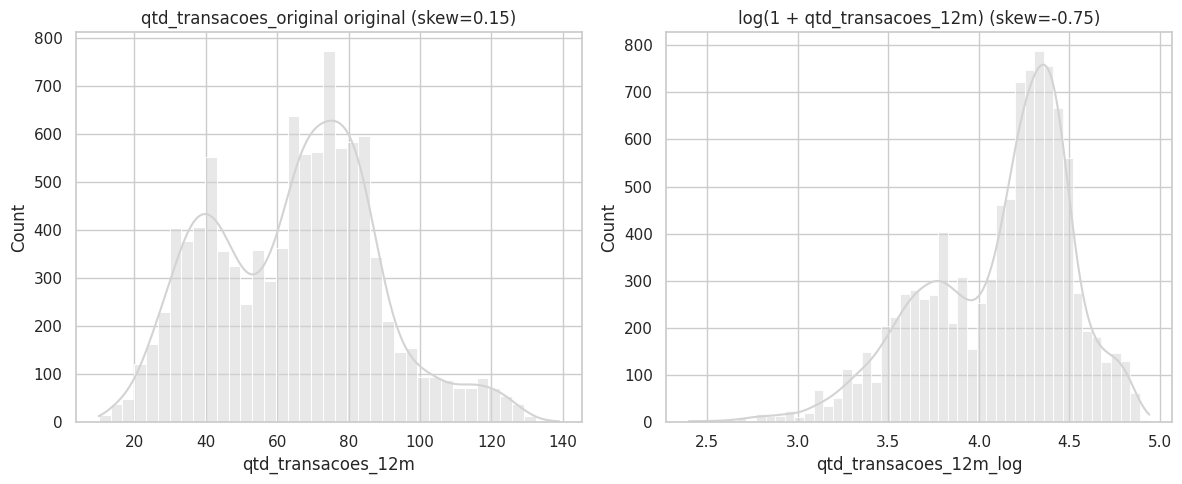

In [ ]:
df["qtd_transacoes_12m_log"] = np.log1p(df["qtd_transacoes_12m"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="qtd_transacoes_12m", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"qtd_transacoes_original original (skew={df['qtd_transacoes_12m'].skew():.2f})")


sns.histplot(data=df, x="qtd_transacoes_12m_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + qtd_transacoes_12m) (skew={df['qtd_transacoes_12m_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

**Nesse caso a transformações logarítmica aumentou a assimetria negativa, que anteriormente era positiva**

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
idade,46.33,46.00,8.02,26.00,73.00,-0.03,-0.29
dependentes,2.35,2.00,1.30,0.00,5.00,-0.02,-0.68
meses_de_relacionamento,35.93,36.00,7.99,13.00,56.00,-0.11,0.40
qtd_produtos,3.81,4.00,1.55,1.00,6.00,-0.16,-1.01
iteracoes_12m,2.46,2.00,1.11,0.00,6.00,0.01,0.00
meses_inativo_12m,2.34,2.00,1.01,0.00,6.00,0.63,1.10
qtd_transacoes_12m,64.86,67.00,23.47,10.00,139.00,0.15,-0.37


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
idade,-0.034,-0.034,-0.289,-0.289,0.0,0.0
dependentes,-0.021,-0.021,-0.683,-0.683,0.0,0.0
meses_de_relacionamento,-0.107,-0.107,0.400,0.400,0.0,0.0
qtd_produtos,-0.162,-0.162,-1.006,-1.006,0.0,0.0
iteracoes_12m,0.011,0.011,0.001,0.001,0.0,0.0
meses_inativo_12m,0.633,0.633,1.099,1.099,0.0,0.0
qtd_transacoes_12m,0.154,0.154,-0.367,-0.367,0.0,0.0


**Pra discutir:** os valores mudaram muito?

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.


# **(Não faz sentido no meu dataset rodar a celúla de cima visto que meus dados faltantes eram qualitativos e não foi removido nenhum outlier. Portanto os dados quantitativos continuam exatamente os mesmos)**

**Visualizando antes x depois, lado a lado**

Utilização de histograma para visualizar o antes e o depois das variáveis qualitativas

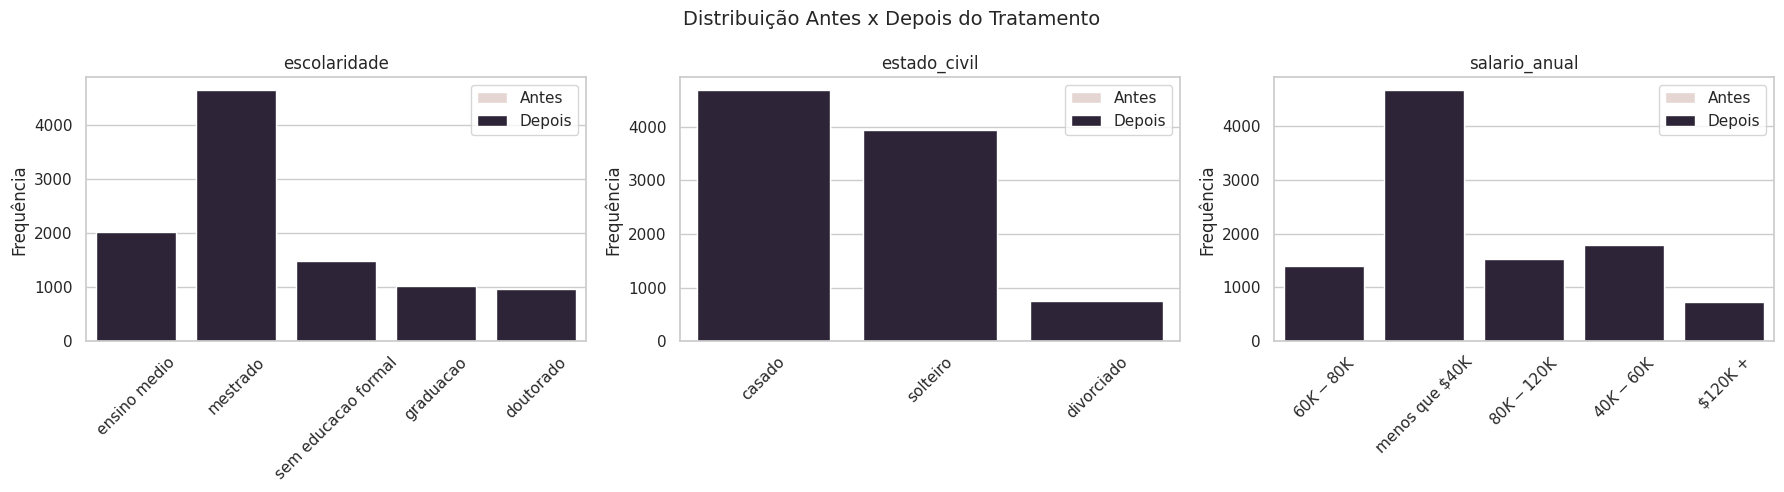

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ["escolaridade", "estado_civil", "salario_anual"]):

    sns.countplot(
        data=df_antes,
        x=col,
        color=COR_CONTEXTO,
        label="Antes",
        ax=ax
    )

    sns.countplot(
        data=df,
        x=col,
        color=COR_DESTAQUE,
        label="Depois",
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Frequência")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)

plt.tight_layout()

plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem?

Sim, se sobrepõem, tanto que não é possível visualizar a tabela de antes. Creio que o de se esperar quando não se retira nenhum outlier e apenas adiciona a moda no lugar dos dados ausentes

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- id ---
           absoluta  relativa
id                           
714337233         1       0.0
768805383         1       0.0
818770008         1       0.0
713982108         1       0.0
769911858         1       0.0
...             ...       ...
709327383         1       0.0
806160108         1       0.0
753327333         1       0.0
709967358         1       0.0
714885258         1       0.0

[10127 rows x 2 columns]
\n--- sexo ---
      absoluta  relativa
sexo                    
F         5358     0.529
M         4769     0.471
\n--- escolaridade ---
                     absoluta  relativa
escolaridade                           
mestrado                 4647     0.459
ensino medio             2013     0.199
sem educacao formal      1487     0.147
graduacao                1013     0.100
doutorado                 967     0.095
\n--- estado_civil ---
              absoluta  relativa
estado_civil                    
casado            4687      0.50
solteiro          3943      0.4

A maior parte de pessoas contidas nesse dataset não possuem uma renda mensal tão alta, transitando entre 3 a 4 mil reais. O alto número de cartões "blue", "mais simples", também testemunham positivamente para esse fato.

#### Visualizando as frequências

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

Error in callback <function _draw_all_if_interactive at 0x7e31973636a0> (for post_execute):


KeyboardInterrupt: 

Error in callback <function flush_figures at 0x7e3197360ae0> (for post_execute):


KeyboardInterrupt: 

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

**(Por algum motivo eu não consigo rodar essa célula anterior)**

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `status_financeiro`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["status_financeiro"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
id,10127.0,1.00,1.000
sexo,2.0,1.12,0.998
escolaridade,5.0,4.81,0.879
estado_civil,3.0,6.27,0.831
salario_anual,5.0,6.43,0.877
tipo_cartao,4.0,471.80,0.208
limite_credito,9272.0,11.00,0.990
valor_transacoes_12m,10035.0,3.00,1.000
status_financeiro,2.0,5.22,0.636


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `status_financeiro` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

A classe menos balanceada aparece sendo a de tipo de cartão, com uma razão de balaceamento altíssima e baixa entropia normalizada. A váriavel alvo status_financieor distoa um pouco do resto do dataset, visto que a maioria das outras variáveis parecem estar muito bem balanceadas, por mais que seus resultados não sejam tão ruins.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

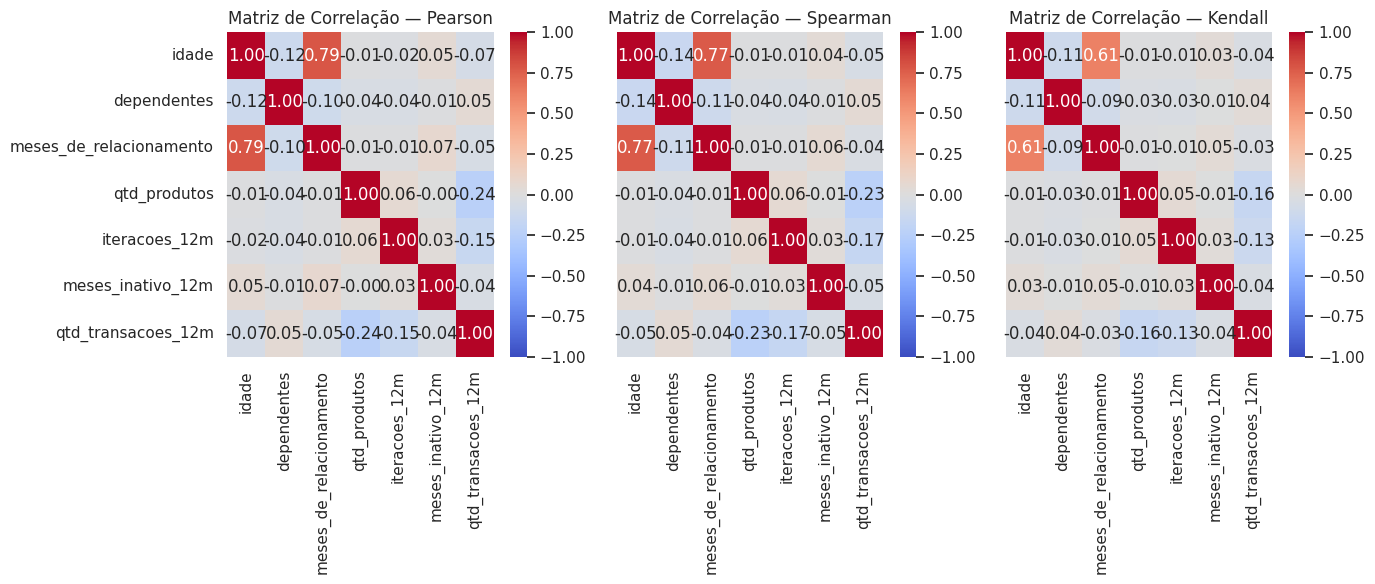

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 6),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

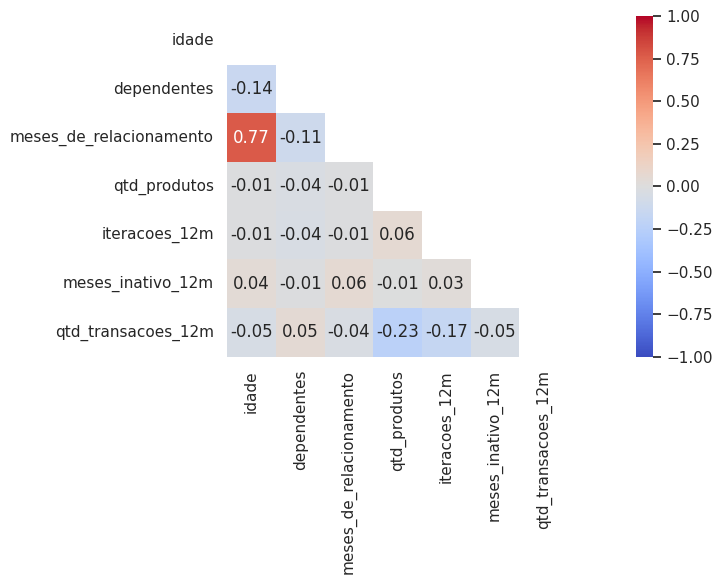

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(14, 6))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

**Resposta:** Não há muita divergência entre pearson e spearmann

#### Dispersão (scatter) entre duas variáveis quantitativas

Comparação entre meses de relacionamento e idade. Além de possuir maior correlação estátistica também possui uma certa relação de domínio, relacionada ao tempo.

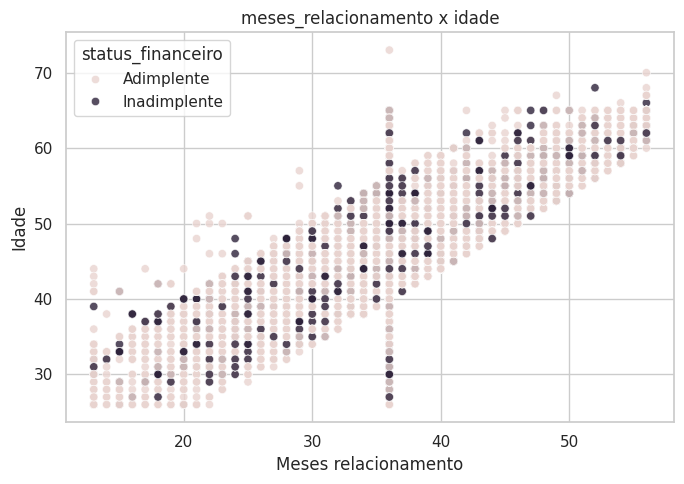

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="meses_de_relacionamento", y="idade", hue="status_financeiro",
                palette={"Adimplente": COR_CONTEXTO, "Inadimplente": COR_DESTAQUE}, alpha=0.8)
plt.title("meses_relacionamento x idade")
plt.xlabel("Meses relacionamento")
plt.ylabel("Idade")
plt.tight_layout()
plt.show()


**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

**Reposta:** O gráfico de dispersão condiz com a correlação. Pearson e spearman possuem praticamente o mesmo valor. Por Pearson anlisar de forma linear e as correlações possuirem valores parecidos faz sentido o scatter plot aparecer de forma linear e quase diretamente proporcional.

#### Outliers bivariados

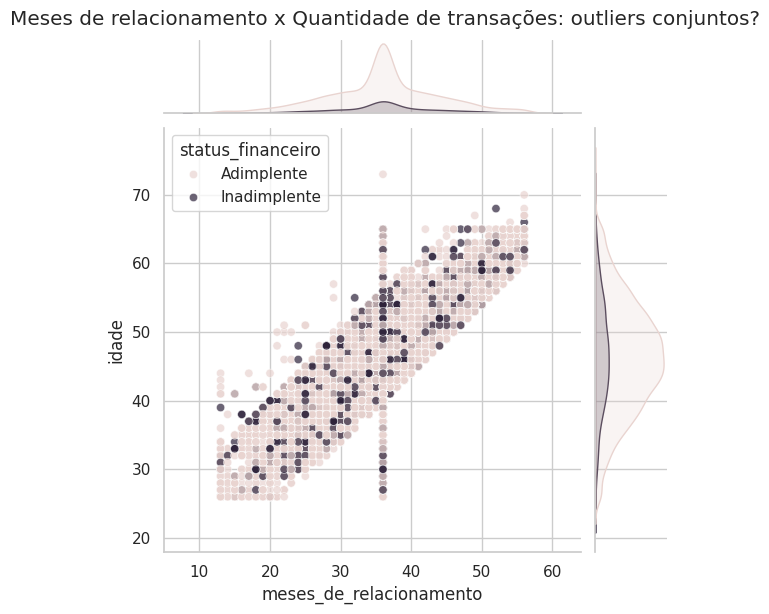

In [ ]:
sns.jointplot(data=df, x="meses_de_relacionamento", y="idade", hue="status_financeiro",
              palette={"Adimplente": COR_CONTEXTO, "Inadimplente": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Meses de relacionamento x Idade: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `meses_de_relacionamento` e `idade`?

Não. Não há nenhum tipo de concentração de classe em regiões de outliers que indique uma relação incomum entre essas duas váriaveis. O que é possível perceber por meio dessa distribuição é que existe uma maior número de pessoas inadimplentes com um número de meses de relacionamento pequeno

#### Análise Multivariada

##### Matriz de Correlação

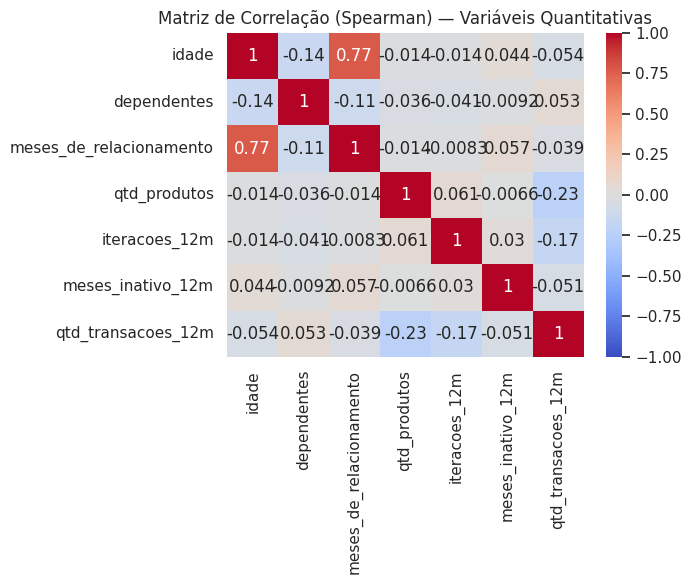

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

A maior relação é entre meses de relacionamento e idade, porém nem a correlação
nem uma proximidade de sentido no domínio ( além da temporalidade) indica uma redundância ou algo no modelo causa->efeito.

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

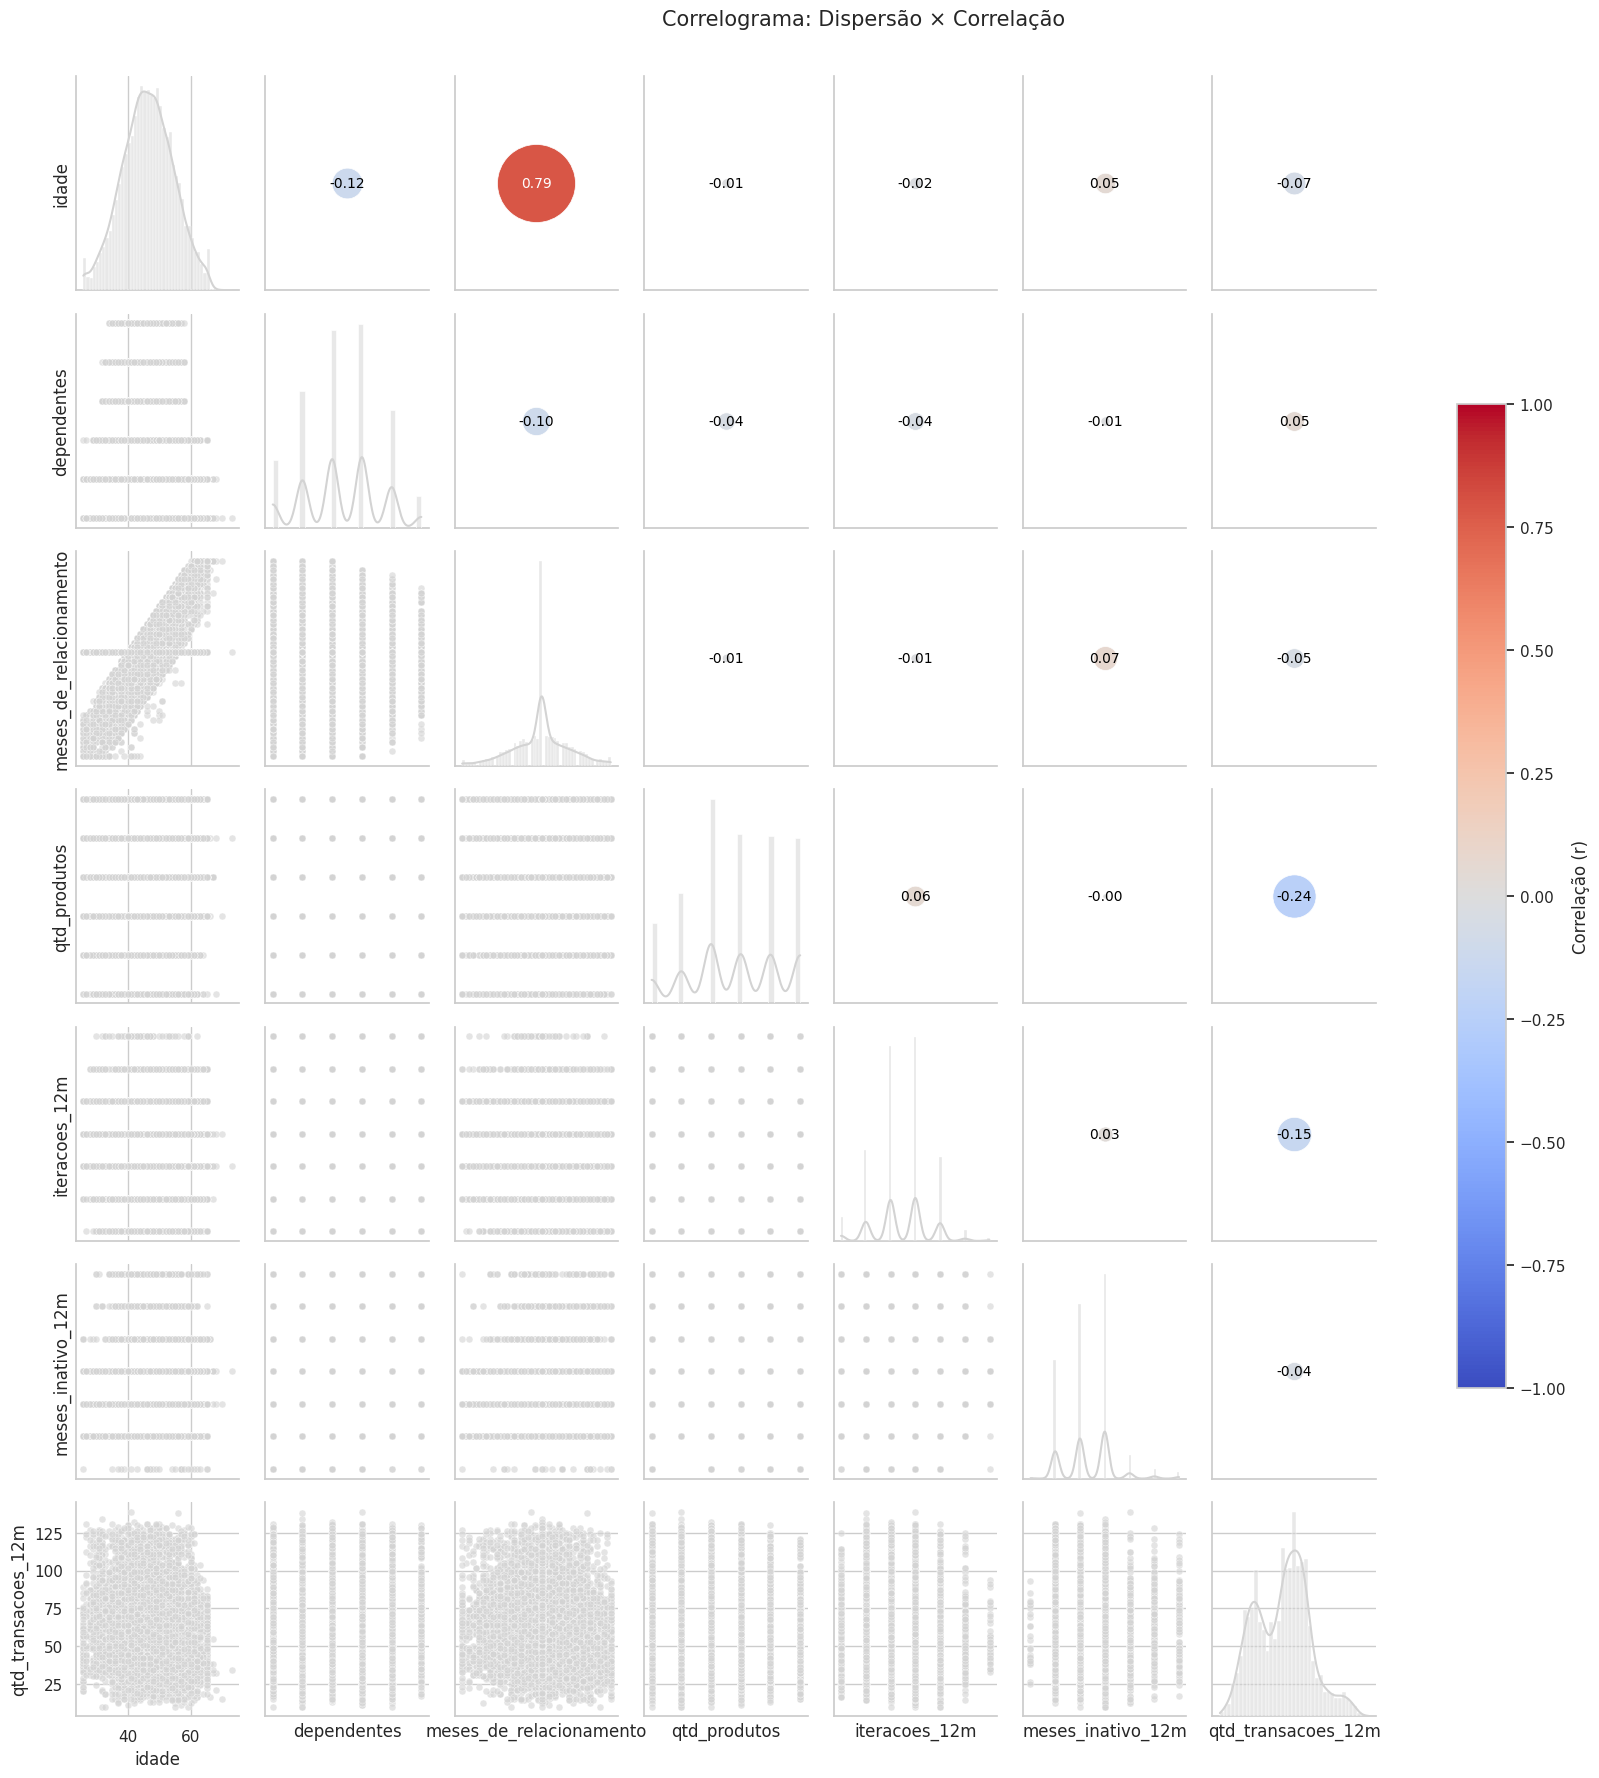

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




Sintese da EDA:


*   Há um certo desbalanceamento entre dentro da váriavel alvo, "status_financeiro", o que pode causar dificuldades no treinamento de modelos de machine learning.
*   As váriaveis possuem baixos níves de correlação, excetuando-se as váriaveis de meses de relacionamento e idade, que possuem uma maior proximidade inclusive devido à sua relação de temporalidade.
*   A maior parte das pessoas contidas nesse dataset não possui uma renda tão alta, em volta dos 3 mil reais mensais. Ao mesmo tempo possui um número de Adimplentes muito maior do que o de inadimplentes, o que mostra que não necessariamente uma baixa renda significa dívidas não pagas.
*   De acordo com o ponto acima, um modelo de machine learning poderia se beneficiar disso, visto que não faria essa relação de forma imediata.





Foi utilizado o CHATGPT para geração de códigos "pandas" e para entendimento de gráficos e conceitos. Os resultados em sua grande maioria foram aceitos visto que eram mais diretos.